## DataSet

**DataSet** - Obesity Levels

This dataset include data for the estimation of obesity levels in individuals from the countries of Mexico, Peru and Colombia, based on their eating habits and physical condition. 

***Данные о человеке***

| Столбец | Смысл и тип | Как интерпретировать значения |
|---|---|---|
| `Gender` | Пол, категориальный | `Female` — женский; `Male` — мужской. У категорий нет числового порядка. |
| `Age` | Возраст, числовой | В годах: `21` — 21 год. Дробные значения могут появляться вследствие синтетической генерации. |
| `Height` | Рост, числовой | **В метрах**: `1.75` — 175 см. |
| `Weight` | Масса тела, числовой | **В килограммах**: `82.5` — 82,5 кг. |
| `family_history_with_overweight` | Наличие избыточного веса у родственников, бинарный | `yes` — у кого-либо из членов семьи был или есть избыточный вес; `no` — нет. Это ответ о семейной истории, а не результат генетического анализа. |

***Питание и напитки***

| Столбец | Что означает | Значения и их интерпретация |
|---|---|---|
| `FAVC` | Частое употребление высококалорийной пищи | `yes` — да; `no` — нет. Не показывает конкретное количество калорий. |
| `FCVC` | Частота употребления овощей | `1` — никогда; `2` — иногда; `3` — всегда. Чем больше значение, тем регулярнее человек ест овощи. |
| `NCP` | Количество основных приёмов пищи в день | В данных — значения от `1` до `4`: `1`, `2`, `3` соответствуют количеству приёмов пищи; `4` обозначает более трёх. В исходной анкете варианты сгруппированы: «1–2», «три», «более трёх». |
| `CAEC` | Еда между основными приёмами пищи — перекусы | `no` — не перекусывает; `Sometimes` — иногда; `Frequently` — часто; `Always` — всегда. |
| `CH2O` | Ежедневное потребление воды | `1` — менее 1 л; `2` — от 1 до 2 л; `3` — более 2 л. |
| `CALC` | Частота употребления алкоголя | `no` — не употребляет; `Sometimes` — иногда; `Frequently` — часто; `Always` — всегда. Конкретное количество алкоголя и точные интервалы частоты не указаны. |

***Образ жизни***

| Столбец | Что означает | Значения и их интерпретация |
|---|---|---|
| `SMOKE` | Курение, бинарный признак | `yes` — курит; `no` — не курит. Количество сигарет и стаж не указаны. |
| `SCC` | Контроль потребляемых калорий, бинарный признак | `yes` — следит за калорийностью питания; `no` — не следит. `yes` не обязательно означает дефицит калорий или соблюдение диеты. |
| `FAF` | Частота физической активности, порядковая шкала | `0` — отсутствует; `1` — 1–2 дня в неделю; `2` — 2–4 дня; `3` — 4–5 дней. Число обозначает категорию, а не точное число тренировок. |
| `TUE` | Время использования устройств: телефона, компьютера, телевизора и т. п., порядковая шкала | `0` — 0–2 часа; `1` — 3–5 часов; `2` — более 5 часов в день. **`0` не означает полное отсутствие использования устройств.** |
| `MTRANS` | Обычно используемый способ передвижения, категориальный признак | `Automobile` — автомобиль; `Motorbike` — мотоцикл; `Bike` — велосипед; `Public_Transportation` — общественный транспорт; `Walking` — пешком. |

***Target - NObeyesdad***

| Значение | Значение на русском |
|---|---|
| `Insufficient_Weight` | Недостаточная масса тела |
| `Normal_Weight` | Нормальная масса тела |
| `Overweight_Level_I` | Избыточная масса тела I уровня |
| `Overweight_Level_II` | Избыточная масса тела II уровня |
| `Obesity_Type_I` | Ожирение I степени |
| `Obesity_Type_II` | Ожирение II степени |
| `Obesity_Type_III` | Ожирение III степени |

## Hypotheses

1. Случайный лес покажет более высокий средний F1 macro на кросс-валидации, чем одиночное решающее дерево.
2. Дерево с глубиной, выбранной из заранее заданного набора ограничений, покажет более высокий средний F1 macro на кросс-валидации, чем дерево без ограничения глубины.
3. Стандартизация числовых признаков с помощью StandardScaler повысит средний F1 macro логистической регрессии по сравнению с моделью без масштабирования.
4. Добавление признака FAF × TUE повысит средний F1 macro логистической регрессии по сравнению с использованием исходных признаков без этого взаимодействия.
5. После исключения CH2O, NCP и SCC средний F1 macro случайного леса снизится не более чем на 0,01 по сравнению с моделью на полном наборе признаков.

## Download DataSet

In [276]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt


df = pd.read_csv("data/Obesity_Levels_DataSet.csv")

In [277]:
df.shape

(2111, 17)

In [278]:
print(f"All columns:\n{df.columns.tolist()}")

All columns:
['Age', 'Gender', 'Height', 'Weight', 'CALC', 'FAVC', 'FCVC', 'NCP', 'SCC', 'SMOKE', 'CH2O', 'family_history_with_overweight', 'FAF', 'TUE', 'CAEC', 'MTRANS', 'NObeyesdad']


In [279]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2111 non-null   str    
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  family_history_with_overweight  2111 non-null   str    
 12  FAF                             2111 non-null

## EDA

In [280]:
df.head()

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.0,Female,1.62,64.0,no,no,2.0,3.0,no,no,2.0,yes,0.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1,21.0,Female,1.52,56.0,Sometimes,no,3.0,3.0,yes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,23.0,Male,1.80,77.0,Frequently,no,2.0,3.0,no,no,2.0,yes,2.0,1.0,Sometimes,Public_Transportation,Normal_Weight
3,27.0,Male,1.80,87.0,Frequently,no,3.0,3.0,no,no,2.0,no,2.0,0.0,Sometimes,Walking,Overweight_Level_I
4,22.0,Male,1.78,89.8,Sometimes,no,2.0,1.0,no,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


**Необходимые статистики**

In [281]:
df.describe().round(2)

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.00,2111.00,2111.00,2111.00,2111.00,2111.00,2111.00,2111.00
mean,24.31,1.70,86.59,2.42,2.69,2.01,1.01,0.66
std,6.35,0.09,26.19,0.53,0.78,0.61,0.85,0.61
min,14.00,1.45,39.00,1.00,1.00,1.00,0.00,0.00
25%,19.95,1.63,65.47,2.00,2.66,1.58,0.12,0.00
50%,22.78,1.70,83.00,2.39,3.00,2.00,1.00,0.63
75%,26.00,1.77,107.43,3.00,3.00,2.48,1.67,1.00
max,61.00,1.98,173.00,3.00,4.00,3.00,3.00,2.00


**Проверка на наличие null**

In [282]:
df.isnull().sum()

Age                               0
Gender                            0
Height                            0
Weight                            0
CALC                              0
FAVC                              0
FCVC                              0
NCP                               0
SCC                               0
SMOKE                             0
CH2O                              0
family_history_with_overweight    0
FAF                               0
TUE                               0
CAEC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

**Дубликаты**

In [283]:
def count_duplicates_percent(duplicates_count, dataframe) -> float:
    return 100 * duplicates_count / len(dataframe)


duplicated_strings_count = int(df.duplicated().sum())
dupcilat_percent = count_duplicates_percent(duplicated_strings_count, df)

print(f"Amount duplicates = {duplicated_strings_count}")
print(f"Duplicates percent = {dupcilat_percent}")

Amount duplicates = 24
Duplicates percent = 1.1369019422074846


In [284]:
df[df.duplicated(keep="first")]

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
98,21.0,Female,1.52,42.0,Sometimes,no,3.0,1.0,no,no,1.0,no,0.0,0.0,Frequently,Public_Transportation,Insufficient_Weight
106,25.0,Female,1.57,55.0,Sometimes,yes,2.0,1.0,no,no,2.0,no,2.0,0.0,Sometimes,Public_Transportation,Normal_Weight
174,21.0,Male,1.62,70.0,Sometimes,yes,2.0,1.0,no,no,3.0,no,1.0,0.0,no,Public_Transportation,Overweight_Level_I
179,21.0,Male,1.62,70.0,Sometimes,yes,2.0,1.0,no,no,3.0,no,1.0,0.0,no,Public_Transportation,Overweight_Level_I
184,21.0,Male,1.62,70.0,Sometimes,yes,2.0,1.0,no,no,3.0,no,1.0,0.0,no,Public_Transportation,Overweight_Level_I
209,22.0,Female,1.69,65.0,Sometimes,yes,2.0,3.0,no,no,2.0,yes,1.0,1.0,Sometimes,Public_Transportation,Normal_Weight
309,16.0,Female,1.66,58.0,no,no,2.0,1.0,no,no,1.0,no,0.0,1.0,Sometimes,Walking,Normal_Weight
460,18.0,Female,1.62,55.0,no,yes,2.0,3.0,no,no,1.0,yes,1.0,1.0,Frequently,Public_Transportation,Normal_Weight
467,22.0,Male,1.74,75.0,no,yes,3.0,3.0,no,no,1.0,yes,1.0,0.0,Frequently,Automobile,Normal_Weight
496,18.0,Male,1.72,53.0,Sometimes,yes,2.0,3.0,no,no,2.0,yes,0.0,2.0,Sometimes,Public_Transportation,Insufficient_Weight


Одинаковые записи не должны попасть в обучение и тест

In [285]:
df_without_dup = df.drop_duplicates()

print(f"Размер после очистки: {df_without_dup.shape}")
print(f"Осталось дубликатов: {df_without_dup.duplicated().sum()}")
print(f"Удалено строк: {len(df) - len(df_without_dup)}")

Размер после очистки: (2087, 17)
Осталось дубликатов: 0
Удалено строк: 24


**Повторная проверка количество строк и столбцов**

In [286]:
df_without_dup.shape

(2087, 17)

### Распределение по классам - target Y

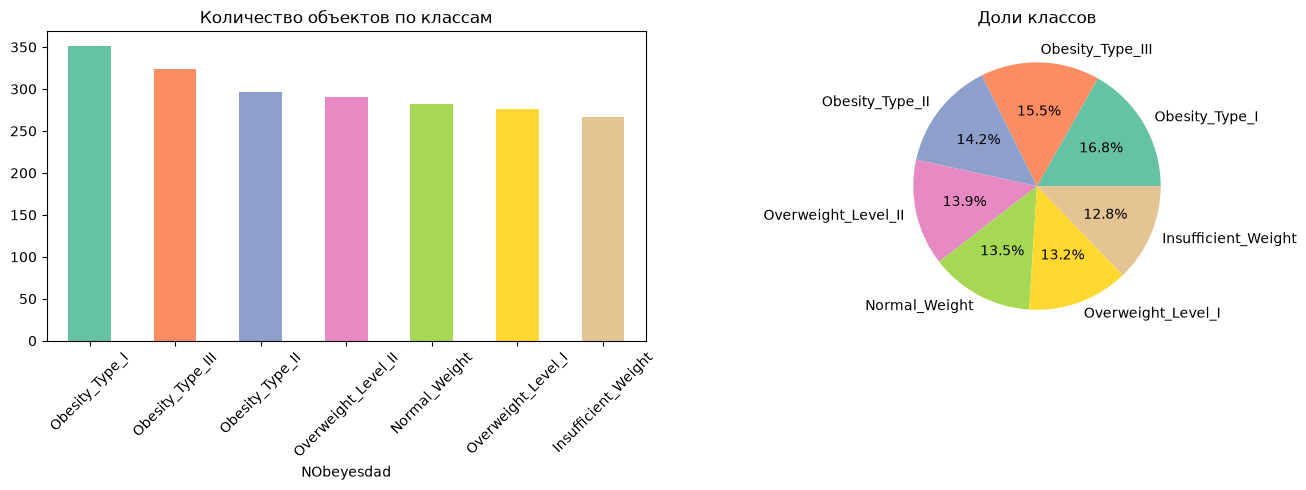

In [287]:
target_column = "NObeyesdad"
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_without_dup[target_column].value_counts().plot.bar(ax=axes[0], color=sb.color_palette("Set2"))
axes[0].set_title("Количество объектов по классам")
axes[0].tick_params(axis='x', rotation=45)

df_without_dup[target_column].value_counts(normalize=True).plot.pie(ax=axes[1], autopct='%1.1f%%', colors=sb.color_palette('Set2'))
axes[1].set_ylabel('')
axes[1].set_title('Доли классов')
plt.tight_layout()
plt.show()

### Распределение признаков $x_1, x_2, \ldots, x_d$

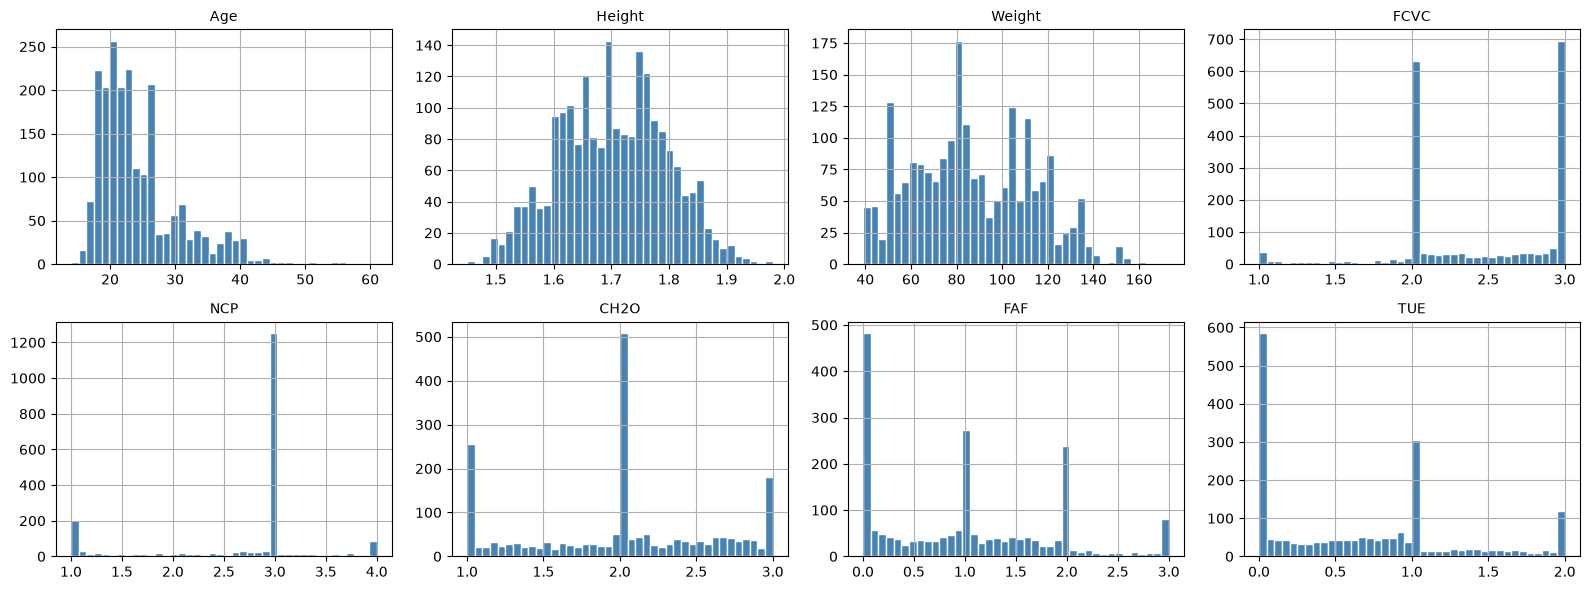

In [288]:
numeric_cols = df_without_dup.select_dtypes(include=np.number).columns.tolist()

n_cols = len(numeric_cols)
n_rows = (n_cols + 3) // 4
fig, axes = plt.subplots(n_rows, 4, figsize=(16, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    df_without_dup[col].hist(bins=40, ax=axes[i], color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=10)

# delete extra figures
# for j in range(len(numeric_cols), len(axes)):
#     axes[j].set_visible(False)
plt.tight_layout()
plt.show()

#### Распределение категориальных признаков

In [289]:
categorized_columns = df_without_dup.select_dtypes(include="string").columns.tolist()
categorized_columns.remove(target_column)

for category in categorized_columns:
    print(f"Amount category {category} = {df_without_dup[category].value_counts()}\n")
    print(f"Caterogy {category} percent = {df_without_dup[category].value_counts(normalize=True) * 100}\n\n")

Amount category Gender = Gender
Male      1052
Female    1035
Name: count, dtype: int64

Caterogy Gender percent = Gender
Male      50.407283
Female    49.592717
Name: proportion, dtype: float64


Amount category CALC = CALC
Sometimes     1380
no             636
Frequently      70
Always           1
Name: count, dtype: int64

Caterogy CALC percent = CALC
Sometimes     66.123622
no            30.474365
Frequently     3.354097
Always         0.047916
Name: proportion, dtype: float64


Amount category FAVC = FAVC
yes    1844
no      243
Name: count, dtype: int64

Caterogy FAVC percent = FAVC
yes    88.356493
no     11.643507
Name: proportion, dtype: float64


Amount category SCC = SCC
no     1991
yes      96
Name: count, dtype: int64

Caterogy SCC percent = SCC
no     95.400096
yes     4.599904
Name: proportion, dtype: float64


Amount category SMOKE = SMOKE
no     2043
yes      44
Name: count, dtype: int64

Caterogy SMOKE percent = SMOKE
no     97.891711
yes     2.108289
Name: proportion

### Кореляционная матрица

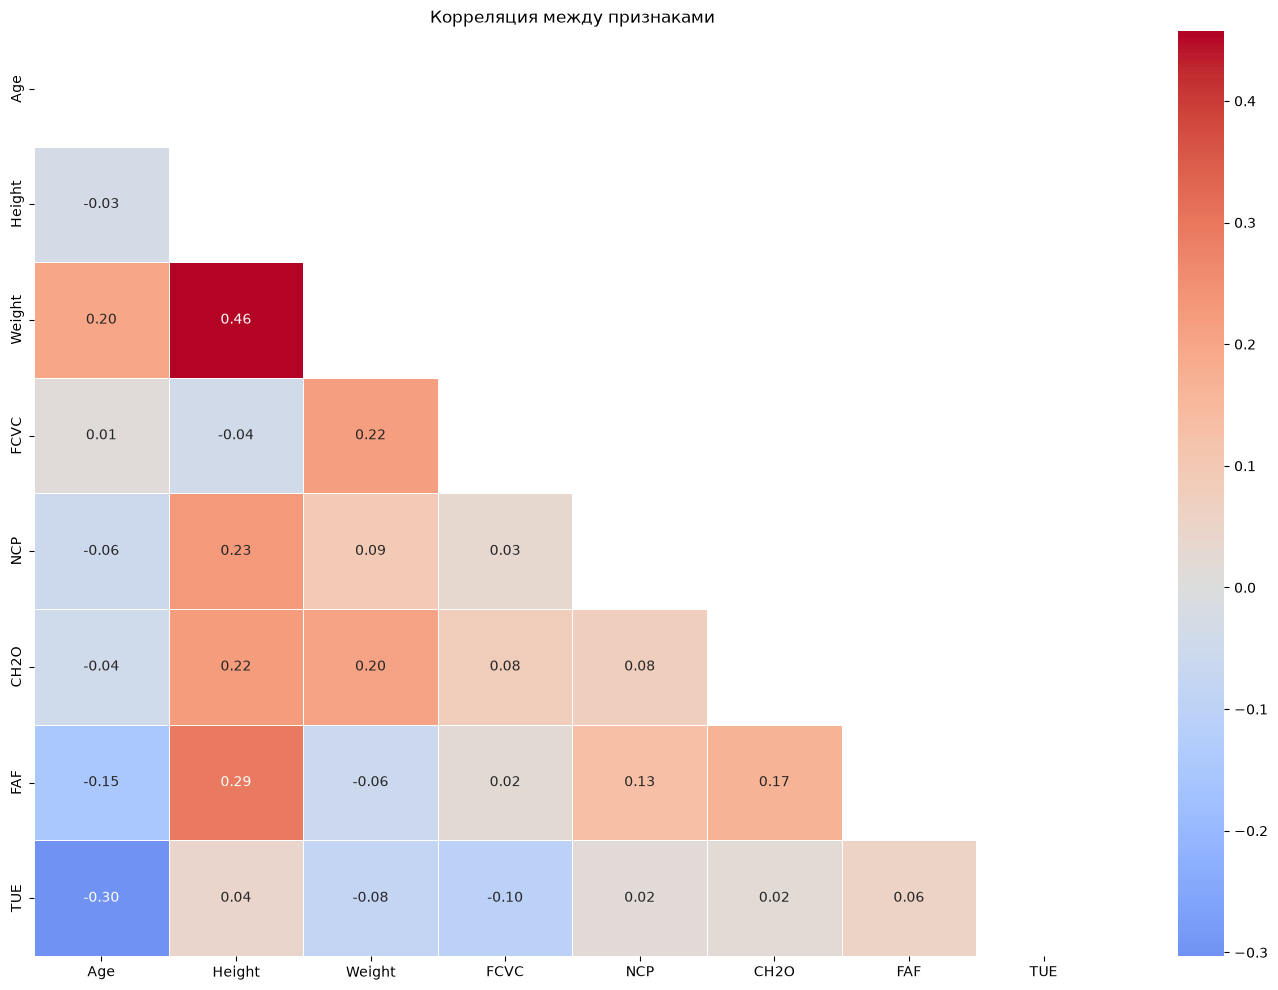

In [290]:
plt.figure(figsize=(14, 10))
corr = df_without_dup[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sb.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Корреляция между признаками')
plt.tight_layout()
plt.show()

### Box-plot признаков по классам

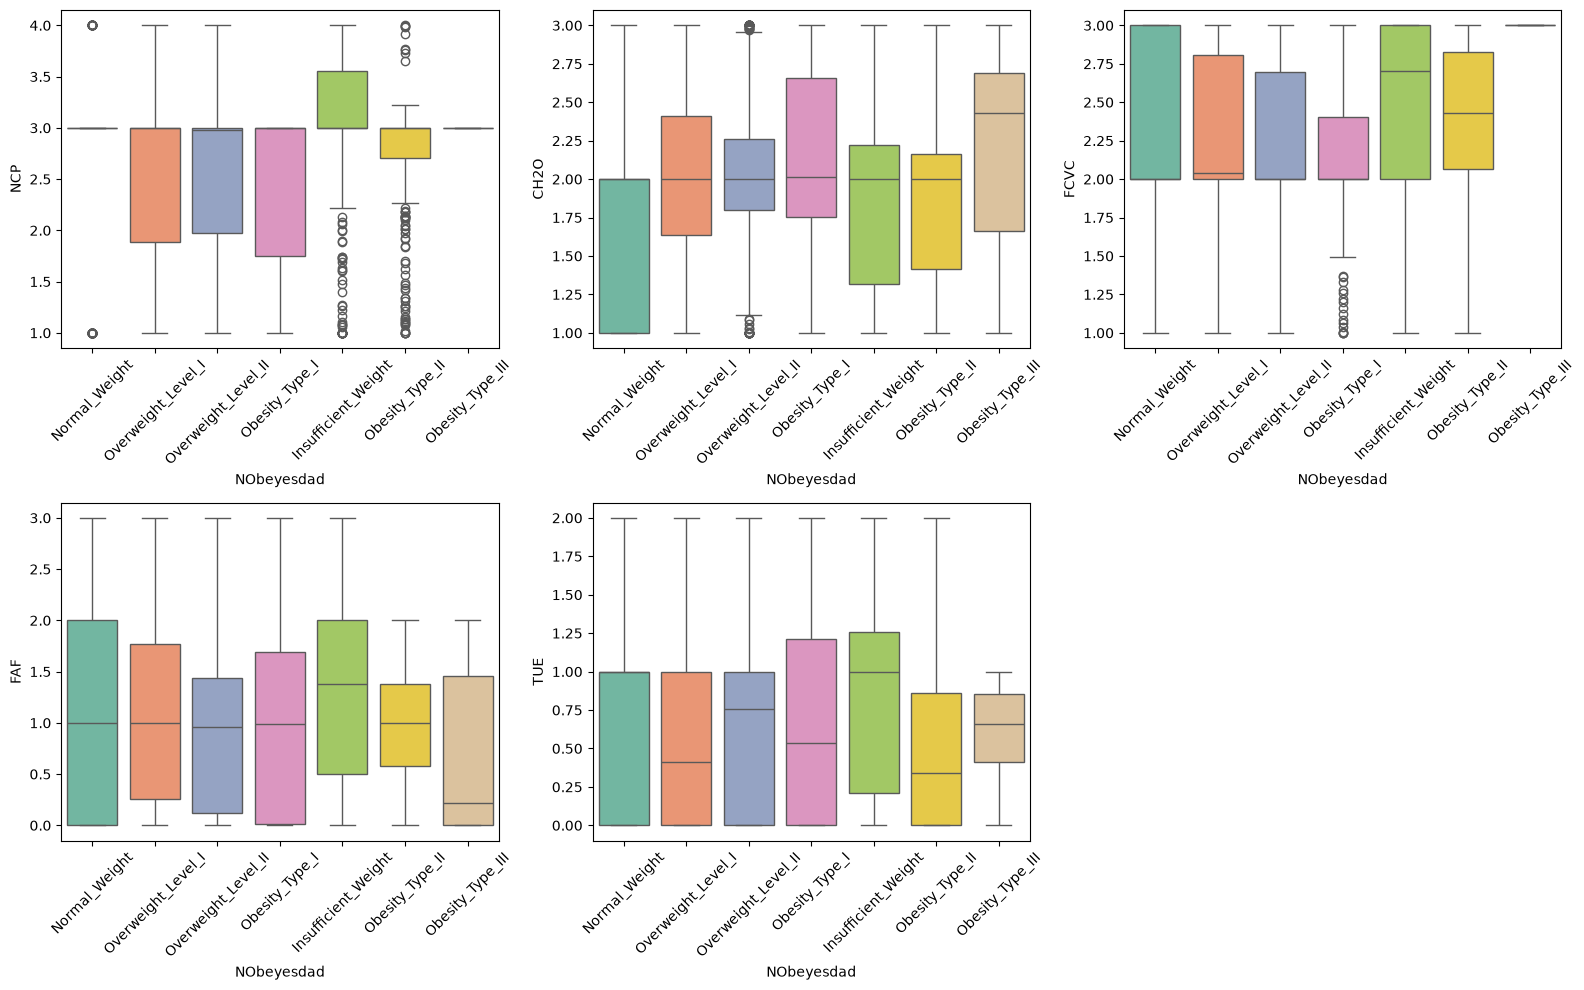

In [291]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
top_features = ["NCP",  "CH2O", "FCVC", "FAF", "TUE"]
for idx, col in enumerate(top_features):
    ax = axes[idx // 3][idx % 3]
    sb.boxplot(
    data=df_without_dup,
    x=target_column,
    y=col,
    hue=target_column,
    ax=ax,
    palette="Set2",
    legend=False
    )
    ax.tick_params(axis='x', rotation=45)
axes = axes.flatten()
axes[5].set_visible(False)
plt.tight_layout()
plt.show()

### PairPlot (ключевые признаки)

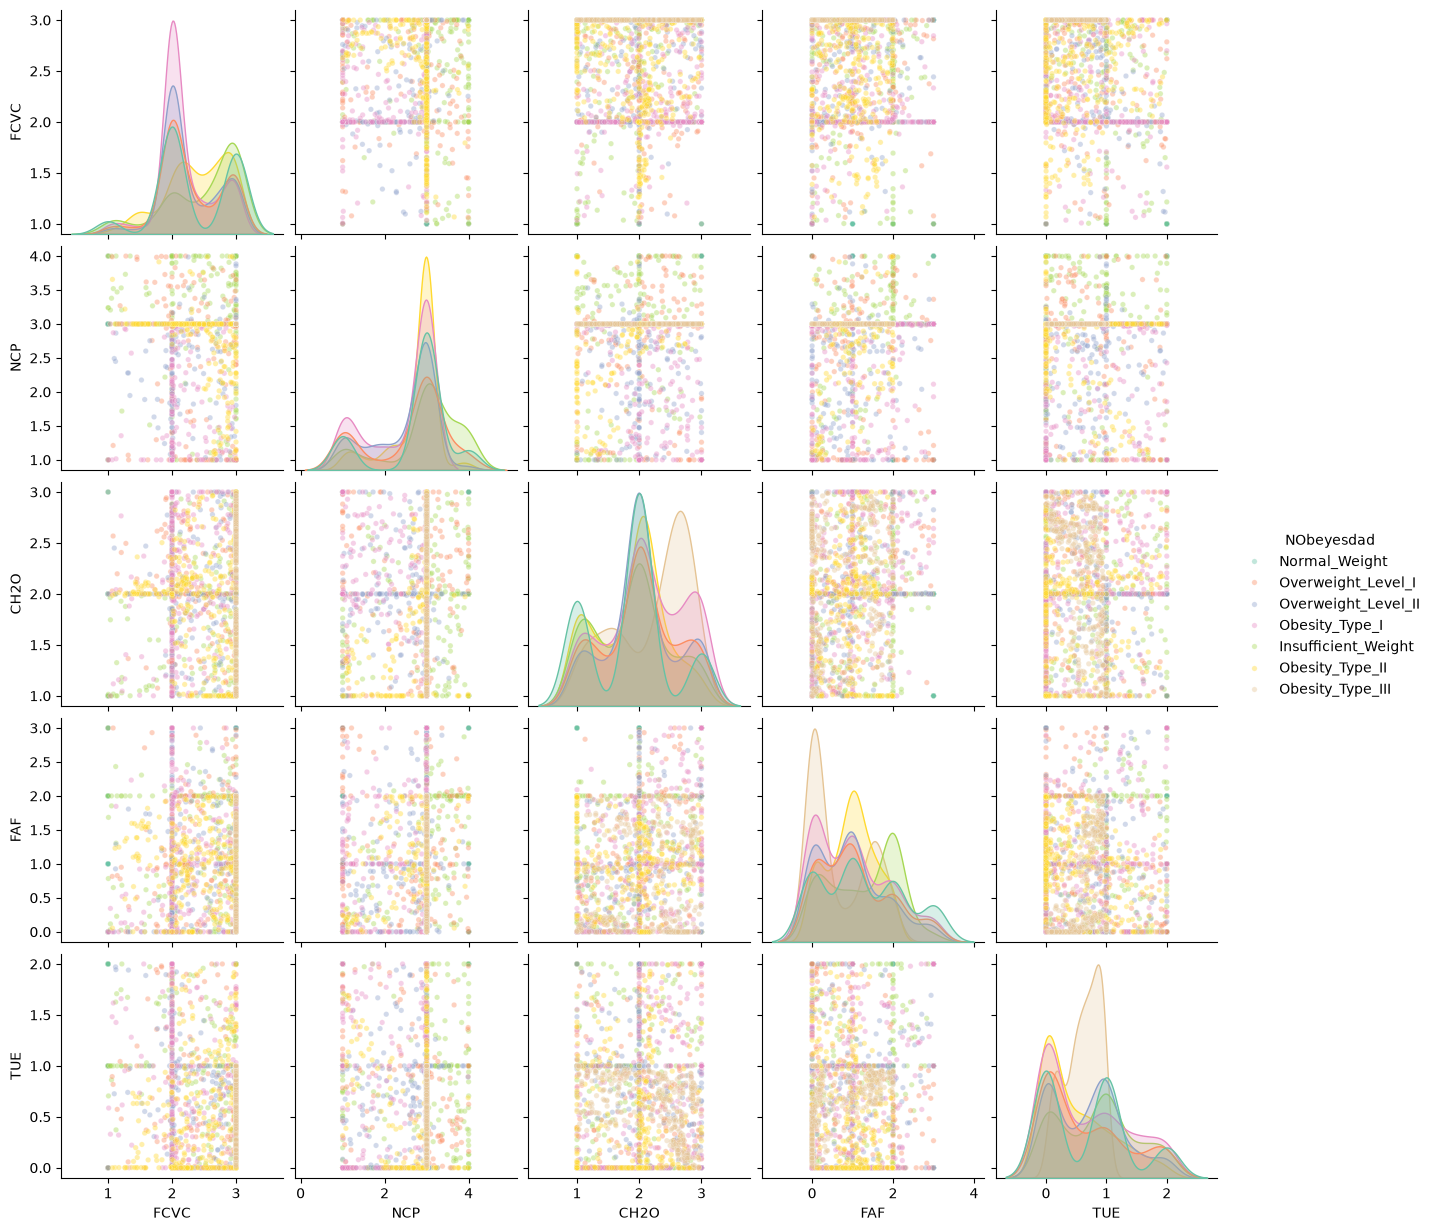

In [292]:
sb.pairplot(df_without_dup[['FCVC', 'NCP', 'CH2O', 'FAF', 'TUE', target_column]],
            hue=target_column, palette='Set2', plot_kws={'alpha': 0.4, 's': 15})
plt.show()

### Выводы по EDA

1. **Строк** - 2087, **столбцов** - 17
2. **Пропусков** нет
3. **Дубликаты** - 24, в процессе EDA были удалены 
4. **Дисбаланс классов** - отсутвует
5. **Распределение** - не выявило аномалий и выбросов
6. **Кореляция** всех признаков - не выше нормы ($<= 0,6$)
7. **PairPloit** - не выявил признаков, по которым можно легко разделить классы

## Подготовка данных

### Для классификации

In [303]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

X_all = df_without_dup.drop(columns=target_column)

print(X_all.shape)
label_encoder = LabelEncoder()
Y_cls = label_encoder.fit_transform(df_without_dup[target_column])

X_train, X_test, Y_train, Y_test = train_test_split(X_all, Y_cls, test_size=0.2, random_state=123, stratify=Y_cls)

(2087, 16)



## Гипотеза №1

Случайный лес покажет более высокий средний F1 macro на кросс-валидации, чем одиночное решающее дерево.

## Гипотеза № 3

Стандартизация числовых признаков с помощью StandardScaler повысит средний F1 macro логистической регрессии по сравнению с моделью без масштабирования.

**Нормирование числовых и категориальных признаков**

Создаем трансформер со *стандартизацией*

In [294]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorized_features = X_train.select_dtypes(include="string").columns.to_list()
numeric_features = X_train.select_dtypes(include=np.number).columns.to_list()

# handle_unknown="ignore" - при появлении новой категории - не выдает ошибку, предскавит класс 0 во всех столбцах, соответсвующими этому признаку
preprocessor_with_standart = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorized_features),
    ("numeric", StandardScaler(), numeric_features)
    ]
)


**Создание Pipeline**

In [295]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression


logic_regression_std = Pipeline([
    ("preprocessor", preprocessor_with_standart),
    ("model", LogisticRegression(max_iter=15000, solver='newton-cholesky'))
])

**Cross-Validation**

In [299]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

**Оценка F1-macro с масштабированием**

In [304]:
cv_model_score_std = cross_val_score(
    logic_regression_std, X=X_train, y=Y_train, cv=CV, scoring="f1_macro"
)

print(f"F1-macro со стандартизацией = {cv_model_score_std.mean()}")
print(f"F1-macro со стандартизацией = {cv_model_score_std}")

predict_codes = cross_val_predict(
    logic_regression_std,
    X_train,
    Y_train,
    cv=CV
)

prediction_table = pd.DataFrame({
    "Правильный класс": label_encoder.inverse_transform(Y_train),
    "Предсказанный класс": label_encoder.inverse_transform(predict_codes),
    "Верно": predict_codes == Y_train
}, index=X_train.index)

prediction_table.head(10)

F1-macro со стандартизацией = 0.8511281962125885
F1-macro со стандартизацией = [0.84214897 0.86881213 0.85924675 0.83340234 0.85203078]


,Правильный класс,Предсказанный класс,Верно
1033,Overweight_Level_II,Overweight_Level_II,True
2056,Obesity_Type_III,Obesity_Type_III,True
1085,Overweight_Level_II,Overweight_Level_I,False
1696,Obesity_Type_II,Obesity_Type_II,True
1452,Obesity_Type_I,Obesity_Type_II,False
421,Insufficient_Weight,Insufficient_Weight,True
1156,Overweight_Level_II,Overweight_Level_II,True
739,Insufficient_Weight,Insufficient_Weight,True
1556,Obesity_Type_II,Obesity_Type_II,True
1567,Obesity_Type_II,Obesity_Type_II,True


**Трансформер без масштабирования**

In [ ]:
preprocessor_without_std = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorized_features),
    ("numeric", "passthrough", numeric_features)
])

**Pipeline с использованием трансформера без масштабирования**

In [ ]:
logic_regression_without_std = Pipeline([
    ("preprocessor", preprocessor_without_std),
    ("model", LogisticRegression(max_iter=15000, solver='newton-cholesky'))
])

**Оценка F1-macro без масштабирования**

In [ ]:
cv_model_score_without_std = cross_val_score(
    logic_regression_without_std, X=X_train, y=Y_train, cv=CV, scoring="f1_macro"
)

print(f"F1-macro без стандартизацией = {cv_model_score_without_std.mean()}")
print(f"F1-macro без стандартизацией по разбиениям = {cv_model_score_without_std}")

F1-macro без стандартизацией = 0.8140437039911221
F1-macro без стандартизацией по разбиениям = [0.80519916 0.83107598 0.82829045 0.78977044 0.81588249]


###  Выводы по гипотезе №3

- $\text{F1-macro с мастабированием}=0,8511$
- $\text{F1-macro без мастабирования}=0,8140$

| Разбиение | Со стандартизацией | Без стандартизации | Разница (c − без) |
|---|---:|---:|---:|
| 1 | 0.8421 | 0.8052 | +0.0369 |
| 2 | 0.8688 | 0.8311 | +0.0377 |
| 3 | 0.8592 | 0.8283 | +0.0310 |
| 4 | 0.8334 | 0.7898 | +0.0436 |
| 5 | 0.8520 | 0.8159 | +0.0361 |
| **Среднее** | **0.8511** | **0.8140** | **+0.0371** |
| Стандартное отклонение (ddof=0) | 0.0124 | 0.0153 | — |


1. **Гипотеза потвердилась** - $\text{F1-macro с мастабированием}>\text{F1-macro без мастабирования}$
2. Из-за отсутсвтвия масштабирования, модели сложнее подбирать коэффиценты, поэтому пришлось увеличивать количество итераций, а в конце поменять метод оптимизаций
3. Заметно увеличение F1 на каждом разбиении у модели со стандартизацией, по сравнению с моделью, без неё

## Гипотеза №4

Добавление признака FAF × TUE повысит средний F1 macro логистической регрессии по сравнению с использованием исходных признаков без этого взаимодействия.

**Создание копии обучающих признаков**

In [ ]:
X_train_intersection = X_train.copy()

print(X_train.shape, X_train_intersection.shape)

(1669, 16) (1669, 16)


**Добавление столбца с произведением FAF и TUE**

In [ ]:
X_train_intersection["FAF_TUE"] = X_train_intersection["FAF"] * X_train_intersection["TUE"]

X_train_intersection["FAF_TUE"].head()
X_train_intersection.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE,FAF_TUE
count,1669.000000,1669.000000,1669.000000,1669.000000,1669.000000,1669.000000,1669.000000,1669.000000,1669.000000
mean,24.240062,1.702002,86.681380,2.416958,2.707692,2.001343,1.001040,0.675331,0.701015
std,6.318822,0.093348,26.187293,0.543494,0.756314,0.610554,0.855194,0.610769,1.062104
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,19.816228,1.630000,65.522744,2.000000,2.701689,1.569082,0.107981,0.000000,0.000000
50%,22.717943,1.700164,83.016968,2.397284,3.000000,2.000000,1.000000,0.656491,0.138722
75%,26.000000,1.769328,107.108190,3.000000,3.000000,2.452986,1.682271,1.000000,1.054682
max,56.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000,6.000000


**Включение нового числовых признаков для стандартизации**

In [ ]:
numeric_features_inter = X_train_intersection.select_dtypes(include=np.number).columns.to_list()

preprocessor_inter = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features_inter),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorized_features),
])

**Оценка нового Pipeline**

In [ ]:
pipeline_inter = Pipeline([
    ("preprocessor", preprocessor_inter),
    ("model", LogisticRegression(max_iter=15000, solver='newton-cholesky'))
])

**Сравнение результата с исходной моделью**

In [ ]:
cv_score_inter = cross_val_score(
    pipeline_inter, X=X_train_intersection, y=Y_train, cv=CV, scoring="f1_macro"
)

print(cv_score_inter)
print(f"F!-score на выборке с дополнительными признаками = {cv_score_inter.mean()}")

[0.83285005 0.87205875 0.86992229 0.84611887 0.85170031]
F!-score на выборке с дополнительными признаками = 0.8545300544489823


### Выводы ао гипотезе #4

- $\text{F1-macro с мастабированием (исходный)}=0,8511$
- $\text{F1-macro с добавлением признака FAF\_TUE}=0,8545$

| Разбиение | С FAF_TUE | Без FAF_TUE (исходная модель) | Разница (с − без) |
|---|---:|---:|---:|
| 1 | 0.8329 | 0.8421 | -0.0093 |
| 2 | 0.8721 | 0.8688 | +0.0032 |
| 3 | 0.8699 | 0.8592 | +0.0107 |
| 4 | 0.8461 | 0.8334 | +0.0127 |
| 5 | 0.8517 | 0.8520 | -0.0003 |
| **Среднее** | **0.8545** | **0.8511** | **+0.0034** |
| Стандартное отклонение (ddof=0) | 0.0148 | 0.0124 | — |

1. **Гипотеза потвердилась** - F1 модели с новым признаком, больше чем у исхожной, из этого можно сделать вывод, что добавление зависимости между FAF и TUE может повысить качество предказания классов
2. Увеличение F1 на 3 из 5 разбиений, позволило повысить F1-macro
3. Но среднее улучшилось немного, а преимущество наблюдается не на всех разбиениях.

## Гипотеза №2

Дерево с глубиной, выбранной из заранее заданного набора ограничений, покажет более высокий средний F1 macro на кросс-валидации, чем дерево без ограничения глубины.

## Гипотеза №5

После исключения CH2O, NCP и SCC средний F1 macro случайного леса снизится не более чем на 0,01 по сравнению с моделью на полном наборе признаков.